In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("../dataset/processed/imdb_reviews_cleaned.csv")

# Basic validation
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

df.head()


Dataset shape: (49582, 3)

Columns: ['review', 'sentiment', 'cleaned_review']

Sentiment distribution:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


,review,sentiment,cleaned_review
0,One of the other reviewers has mentioned that ...,positive,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,positive,a wonderful little production. the filming tec...
2,I thought this was a wonderful way to spend ti...,positive,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,negative,basically there's a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,"petter mattei's ""love in the time of money"" is..."



## 1. Sentiment Distribution

This section visualises the distribution of positive and negative reviews in the cleaned IMDb dataset.


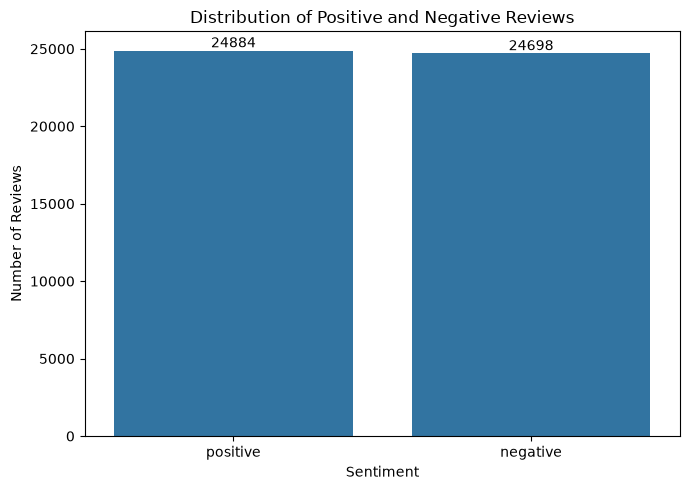

In [2]:

sentiment_counts = df["sentiment"].value_counts().reindex(
    ["positive", "negative"]
)

plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

ax.bar_label(ax.containers[0], fmt="%d")
plt.title("Distribution of Positive and Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


## 2. Review Length Distribution by Sentiment

This section compares the length of positive and negative movie reviews to identify differences in their distributions.


In [4]:

# Calculate review length using the number of words
df["review_length"] = df["cleaned_review"].str.split().str.len()

df.groupby("sentiment")["review_length"].describe()


,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,24698.0,227.239048,163.334056,4.0,127.0,173.0,275.75,1491.0
positive,24884.0,230.860955,175.940652,10.0,124.0,171.0,281.00,2459.0


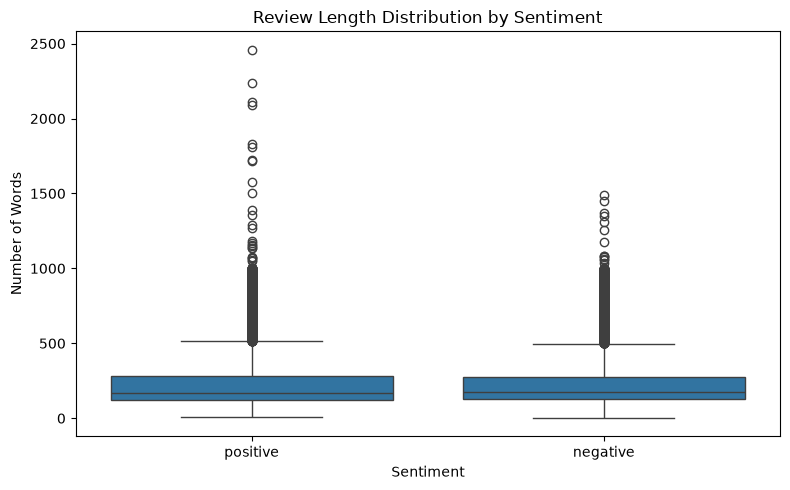

In [5]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="sentiment",
    y="review_length"
)

plt.title("Review Length Distribution by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.show()



## 3. Sentiment Classification Model Performance

This section visualises the performance of the Logistic Regression sentiment classifier using a confusion matrix. It highlights correct predictions and misclassifications for positive and negative reviews.


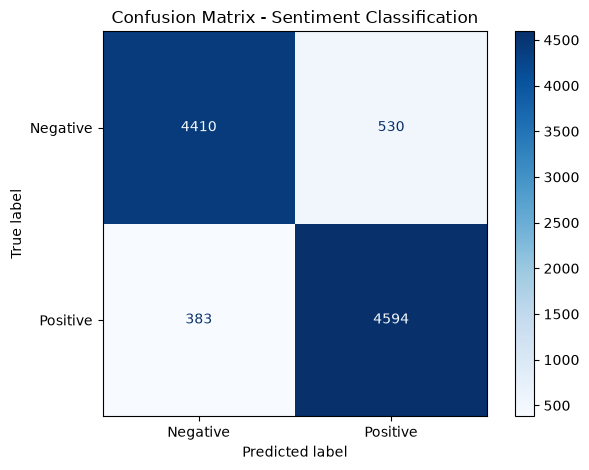

In [9]:

import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion matrix from Notebook 03
cm = np.array([
    [4410, 530],
    [383, 4594]
])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Sentiment Classification")
plt.tight_layout()
plt.show()



## 4. Keyphrase Analysis by Sentiment

This section compares frequently extracted keyphrases from positive and negative IMDb reviews. YAKE identifies potentially important phrases, helping us explore the words and topics present in each group.


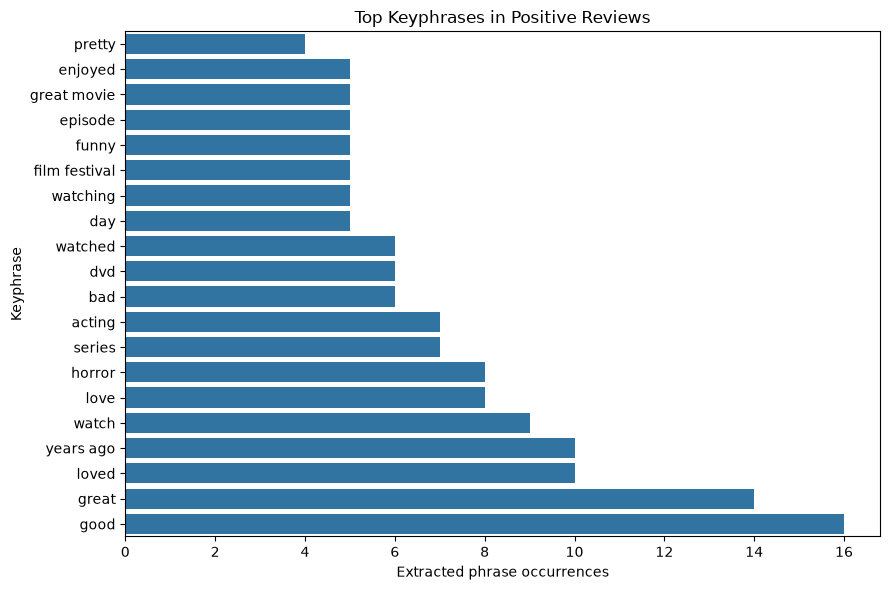

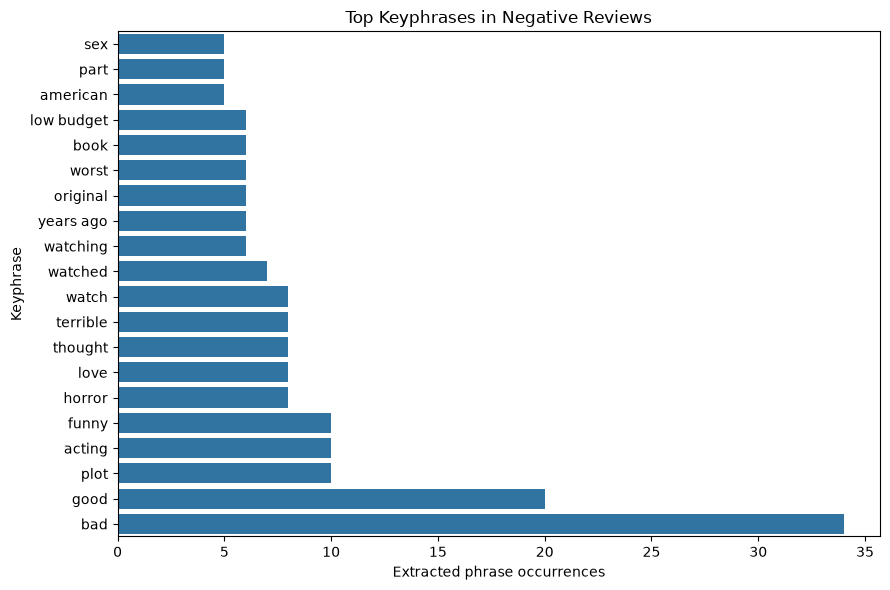

In [10]:

from collections import Counter

# Top keyphrases from Notebook 04
positive_phrases = [
    ("good", 16), ("great", 14), ("years ago", 10),
    ("loved", 10), ("watch", 9), ("horror", 8),
    ("love", 8), ("acting", 7), ("series", 7),
    ("dvd", 6), ("bad", 6), ("watched", 6),
    ("enjoyed", 5), ("episode", 5), ("great movie", 5),
    ("day", 5), ("watching", 5), ("film festival", 5),
    ("funny", 5), ("pretty", 4)
]

negative_phrases = [
    ("bad", 34), ("good", 20), ("acting", 10),
    ("funny", 10), ("plot", 10), ("love", 8),
    ("horror", 8), ("terrible", 8), ("thought", 8),
    ("watch", 8), ("watched", 7), ("book", 6),
    ("low budget", 6), ("worst", 6), ("original", 6),
    ("years ago", 6), ("watching", 6), ("american", 5),
    ("sex", 5), ("part", 5)
]

def plot_top_phrases(phrase_counts, title):
    plot_df = pd.DataFrame(
        phrase_counts, columns=["Phrase", "Count"]
    ).sort_values("Count", ascending=True)

    plt.figure(figsize=(9, 6))
    sns.barplot(data=plot_df, x="Count", y="Phrase")
    plt.title(title)
    plt.xlabel("Extracted phrase occurrences")
    plt.ylabel("Keyphrase")
    plt.tight_layout()
    plt.show()

plot_top_phrases(
    positive_phrases,
    "Top Keyphrases in Positive Reviews"
)

plot_top_phrases(
    negative_phrases,
    "Top Keyphrases in Negative Reviews"
)


## Summary and Key Insights

- **Sentiment distribution:** The cleaned dataset contains 49,582 reviews, with 24,884 positive and 24,698 negative reviews. The two classes are nearly balanced.
- **Review length:** Positive reviews are slightly longer on average than negative reviews, but their median lengths are very similar. Review length alone does not clearly distinguish sentiment.
- **Model performance:** The TF-IDF and Logistic Regression model achieved 90.79% test accuracy. The confusion matrix shows that the model correctly classifies most positive and negative reviews, with some misclassifications.
- **Keyphrase analysis:** YAKE extracts phrases that help explore the content of reviews. Terms such as *great* and *loved* appeared frequently in the positive sample, while *bad*, *terrible*, and *plot* appeared frequently in the negative sample. Some terms occur in both groups, so keyphrases should be interpreted in context.

**Conclusion:** This project combines text preprocessing, machine-learning-based sentiment classification, keyphrase extraction, and visualisation to explore IMDb movie reviews. These components provide a foundation for an interactive application that predicts review sentiment and highlights relevant phrases.

**Limitations:** The sentiment model is evaluated on a held-out test set from this dataset. Keyphrase findings are exploratory and based on a sample of 500 reviews per sentiment; they should not be treated as definitive explanations of audience opinion.